# M04: Ensamblar y evaluar un pliegue magnético

¿Cómo entra una predicción magnética física en un objetivo ponderado por ruido, y cómo evitamos que las filas retenidas participen en el ajuste?

**Nivel 3 · Requisitos: las lecciones M04 de problema directo y M03 de partición espacial; lectura: 30 minutos.**


## Objetivos

Construir un objetivo real de un pliegue de ajuste a partir del protocolo cerrado, un kernel de prismas SimPEG/Geoana, incertidumbre gaussiana y regularización normalizada por volumen. Verificar su derivada numéricamente y evaluar después un modelo congelado en un pliegue de validación separado. Esta lección no ejecuta ni afirma una inversión magnética.

## Preparación

Usa el entorno fijado de la tubería Python 3.12. El notebook no instala paquetes. El levantamiento creado abajo es un control del protocolo, no una adquisición de proveedor ni datos de campo.


Localiza el repositorio e importa las implementaciones exactas. El fixture auxiliar es explícitamente solo de protocolo.

In [1]:
# Importa el protocolo cerrado, el ensamblador real del objetivo y el evaluador de validación.
from pathlib import Path
import sys
import numpy as np

ROOT = Path.cwd()
while not (ROOT / 'data-pipeline').is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / 'data-pipeline'), str(ROOT / 'tests' / 'data')]
from magnetic_survey_support import encode, rehash, request
from magnetic_survey_json import parse_request
from magnetic_survey import plan_geometry
from magnetic_fit_assembly import assemble_magnetic_fit_objective
from magnetic_fold_score import model_q_sha256, score_magnetic_validation_fold


## Datos

El fixture contiene 288 filas receptoras, una malla 3D acotada de celdas activas, un campo inductor uniforme declarado, observaciones de protocolo nulas y desviaciones estándar diagonales condicionales. Fijamos una susceptibilidad inicial no nula para activar la respuesta física; ese valor es el inicio del prior, no la verdad geológica. Recalculamos los hashes antes de analizar.


In [2]:
# Crea una solicitud de protocolo con un modelo inicial no nulo y actualiza el hash del descriptor.
survey = request()
survey['prior']['start_si']['data'] = [0.002] * len(survey['prior']['start_si']['data'])
rehash(survey, 'prior/start_si')
handle = parse_request(encode(survey))
plan = plan_geometry(handle)
meta = handle.metadata()
fit = np.asarray(plan['partition']['folds'][0]['fit_rows']['data'], dtype=np.int64)
validation = np.asarray(plan['partition']['folds'][0]['validation_rows']['data'], dtype=np.int64)
outer = np.asarray(plan['partition']['outer_rows']['data'], dtype=np.int64)
assert not (set(fit) & set(validation) or set(fit) & set(outer) or set(validation) & set(outer))
print('rows:', {'fit': len(fit), 'validation': len(validation), 'outer': len(outer),
               'fit_validation_overlap': len(set(fit) & set(validation)),
               'fit_outer_overlap': len(set(fit) & set(outer))})


rows: {'fit': 144, 'validation': 72, 'outer': 72, 'fit_validation_overlap': 0, 'fit_outer_overlap': 0}


## Método

Para datos secundarios ENU, la respuesta de prismas es lineal en susceptibilidad: `s(q)=G(0.01q)`, con `q=chi/0.01`. En las filas de ajuste seleccionadas, el objetivo gaussiano es `phi_d = ||L^-1 (s(q)-d)||_2^2`; para SD diagonal, `L=diag(sigma)`, y para covarianza completa `LL^T=C` en la submatriz principal seleccionada. El gradiente de datos es `2 J_q^T C^-1(s-d)`. El regularizador usa fracciones de volumen de celdas y caras entre vecinas activas con escalas físicas. Este código ensambla y evalúa esos términos; no elige beta ni optimiza q.

## Estado del arte

La inversión de campos potenciales no es única: un residual pequeño no identifica una geología única. La validación por bloques espaciales estima el comportamiento predictivo bajo la geometría declarada; no demuestra transferencia a campo. El evaluador de abajo está separado deliberadamente del ensamblador de ajuste y devuelve solo métricas agregadas. No puede seleccionar candidatos ni abrir la partición externa.

## Resultados

Planifica el levantamiento original, inspecciona la asignación de filas y confirma que ajuste, validación y partición externa son disjuntos. El planificador geométrico no lee amplitudes ni valores de ruido.

Ensambla solo las filas de ajuste del pliegue 0. El operador directo evalúa la malla y el campo declarados; el regularizador es la implementación WLS fijada de SimPEG.

In [3]:
# Ensambla el kernel SimPEG/Geoana del pliegue, el término gaussiano y el regularizador WLS reales.
assembled = assemble_magnetic_fit_objective(handle, 0)
q = assembled['start_q']
fit_eval = assembled['objective'].evaluate(q)
reg_eval = assembled['regularizer'].evaluate(q)
print({'quantity': assembled['quantity'], 'fit_receivers': len(assembled['fit_rows']),
       'active_cells': len(q), 'chi_start_si': float(q[0] * 0.01),
       'phi_d': fit_eval['phi_d'], 'phi_m': reg_eval['phi'],
       'gradient_inf_q': float(np.linalg.norm(fit_eval['gradient_q'], ord=np.inf)),
       'claim': assembled['claim']})


{'quantity': 'secondary_enu', 'fit_receivers': 144, 'active_cells': 528, 'chi_start_si': 0.002, 'phi_d': 564455.5774028616, 'phi_m': 0.04000000000000001, 'gradient_inf_q': 99242.90528202611, 'claim': 'fit-fold objective assembly only; no inversion performed'}


Representa en el mapa la predicción calculada de la componente este y su residual observado-menos-predicho en las coordenadas ENU reales. Las entradas son un control de protocolo, por lo que estos puntos no deben presentarse como un levantamiento de campo.

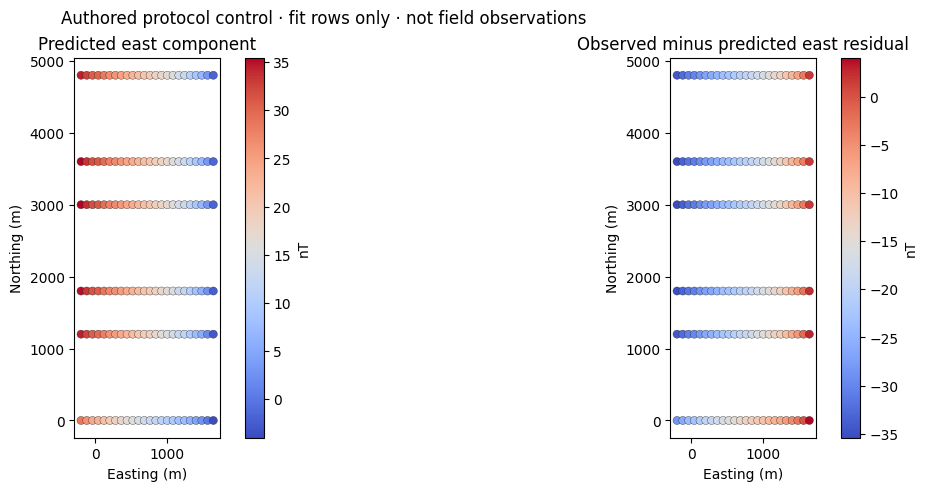

In [4]:
# Grafica las coordenadas físicas de ajuste y los valores calculados de la componente E en nT.
import matplotlib.pyplot as plt
xyz = np.asarray(meta['geometry']['receivers_m']['data'], dtype=np.float64).reshape(-1, 3)[assembled['fit_rows']]
pred = fit_eval['predicted_selected_nT'].reshape(-1, 3)
resid = fit_eval['residual_observed_minus_predicted_nT'].reshape(-1, 3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, values, title in zip(axes, (pred[:, 0], resid[:, 0]),
        ('Predicted east component', 'Observed minus predicted east residual')):
    image = ax.scatter(xyz[:, 0], xyz[:, 1], c=values, s=34, cmap='coolwarm', edgecolors='0.15', linewidths=.25)
    ax.set(title=title, xlabel='Easting (m)', ylabel='Northing (m)', aspect='equal')
    fig.colorbar(image, ax=ax, label='nT')
fig.suptitle('Authored protocol control · fit rows only · not field observations')
plt.show()


Verifica una dirección del modelo con diferencia finita centrada. El operador directo lineal hace suave el objetivo de datos aquí; la verificación comprueba la derivada ensamblada en este punto paramétrico.

In [5]:
# Compara el gradiente analítico con una diferencia centrada en una coordenada de q.
direction = np.zeros_like(q)
direction[0] = 1.0
step = 1e-5
phi_plus = assembled['objective'].evaluate(q + step * direction)['phi_d']
phi_minus = assembled['objective'].evaluate(q - step * direction)['phi_d']
fd = (phi_plus - phi_minus) / (2 * step)
analytic = float(fit_eval['gradient_q'] @ direction)
print({'central_difference': fd, 'analytic_directional_derivative': analytic,
       'absolute_difference': abs(fd - analytic)})
assert np.isclose(fd, analytic, rtol=2e-5, atol=2e-6)


{'central_difference': 845.1026980765163, 'analytic_directional_derivative': 845.1027000534544, 'absolute_difference': 1.9769381651713047e-06}


Congela primero los bytes del modelo y luego evalúa solo las filas de validación del pliegue 0. El resultado contiene métricas agregadas, el hash del modelo y el sello geométrico, pero no vectores de observaciones, predicciones o residuales.

In [6]:
# Congela los bytes canónicos del modelo antes de pedir métricas agregadas al evaluador aislado.
frozen_hash = model_q_sha256(q)
score = score_magnetic_validation_fold(handle, 0, q, frozen_hash)
print(score)
assert score['candidate_selection_performed'] is False
assert score['outer_evaluation_performed'] is False


{'schema': 'magnetic-development-fold-score-1', 'role': 'development-validation-only', 'fold_index': 0, 'geometry_seal_sha256': '0dd0b9f30a60f4165484caf1ec62a532589eebaea3d0db4ad2fd42b2954b7f15', 'model_q_f64le_sha256': '1398404c7c516bf13067d40bf785a523ec861d897b312ef187712cb003f856cb', 'receiver_count': 72, 'observation_count': 216, 'quantity': 'secondary_enu', 'phi_d': 263336.3622307736, 'mean_standardized_quadratic': 1219.1498251424705, 'residual_rms_nT': 17.458163027237934, 'cross_partition_dependence': 'declared_absent', 'contains_observation_vectors': False, 'candidate_selection_performed': False, 'outer_evaluation_performed': False}


## Resumen

Has reproducido un objetivo de ajuste basado en física y una puntuación de validación para un modelo congelado, con procedencia explícita de filas. No se ejecuta búsqueda de beta, ciclo IRLS, reajuste final, evaluación externa, paquete de resultados, aceptación de fuente de campo ni modelo inverso. Las observaciones nulas y la geometría creada son controles del protocolo, no evidencia de precisión científica.

## Referencias

- Marco de campos potenciales y metodología de inversión SimPEG: https://doi.org/10.1016/j.cageo.2015.09.015
- Operador implementado: `data-pipeline/magnetic_forward.py`; objetivo: `data-pipeline/magnetic_objective.py`; evaluador de pliegues: `data-pipeline/magnetic_fold_score.py`.